
# Assignment 10 — Command-Line To-Do Manager Agent Using LangGraph

### Objective
Develop a command-line to-do manager agent that maintains simple task state and allows the user to add, view, complete, remove, and clear tasks.

### Agent Approach
This assignment uses **LangGraph** to organize the to-do manager as a state-based agent.

The agent receives a command, identifies the requested operation, and updates the task list while maintaining its state.

The workflow is:

**User Command → Understand Command → Perform Action → Return Updated State**



### Step 1 — Install and Import Libraries

LangGraph is used to build the agent workflow.


In [1]:
from typing import TypedDict, List, Dict
from langgraph.graph import StateGraph, START, END
import matplotlib.pyplot as plt



### Step 2 — Define the Agent State

The state contains the list of tasks, the current command, and the response produced by the agent.

Each task has a name and a completion status.


In [2]:
class TodoState(TypedDict, total=False):
    command: str
    task_name: str
    task_index: int
    tasks: List[Dict]
    action: str
    response: str



### Step 3 — Define Command Processing

The agent recognizes simple commands such as:

- `add`
- `view`
- `complete`
- `remove`
- `clear`
- `stats`


In [3]:

def process_command(state):
    command = state["command"].strip()
    parts = command.split(maxsplit=1)

    action = parts[0].lower() if parts else ""
    state["action"] = action

    if action == "add" and len(parts) > 1:
        state["task_name"] = parts[1]

    elif action in ["complete", "remove"] and len(parts) > 1:
        try:
            state["task_index"] = int(parts[1]) - 1
        except ValueError:
            state["task_index"] = -1

    return state



### Step 4 — Create the To-Do Actions

These functions perform the operations requested by the user while preserving the current task state.


In [4]:

def perform_action(state):
    action = state["action"]
    tasks = state.get("tasks", [])

    if action == "add":
        task_name = state.get("task_name", "").strip()

        if task_name:
            tasks.append({
                "task": task_name,
                "completed": False
            })
            state["response"] = f"Added task: {task_name}"
        else:
            state["response"] = "Please provide a task name."

    elif action == "view":
        if not tasks:
            state["response"] = "No tasks in the list."
        else:
            lines = ["Current Tasks:"]
            for i, item in enumerate(tasks, start=1):
                mark = "✓" if item["completed"] else " "
                lines.append(f"{i}. [{mark}] {item['task']}")
            state["response"] = "\n".join(lines)

    elif action == "complete":
        index = state.get("task_index", -1)

        if 0 <= index < len(tasks):
            tasks[index]["completed"] = True
            state["response"] = f"Completed task: {tasks[index]['task']}"
        else:
            state["response"] = "Invalid task number."

    elif action == "remove":
        index = state.get("task_index", -1)

        if 0 <= index < len(tasks):
            removed = tasks.pop(index)
            state["response"] = f"Removed task: {removed['task']}"
        else:
            state["response"] = "Invalid task number."

    elif action == "clear":
        tasks.clear()
        state["response"] = "All tasks cleared."

    elif action == "stats":
        completed = sum(item["completed"] for item in tasks)
        pending = len(tasks) - completed

        state["response"] = (
            f"Total tasks: {len(tasks)}\n"
            f"Completed: {completed}\n"
            f"Pending: {pending}"
        )

    else:
        state["response"] = (
            "Unknown command. Use add, view, complete, "
            "remove, clear, or stats."
        )

    state["tasks"] = tasks
    return state


### Step 5 — Build the LangGraph Workflow
The graph connects command processing with the task-management action.

In [5]:

workflow = StateGraph(TodoState)

workflow.add_node("process_command", process_command)
workflow.add_node("perform_action", perform_action)

workflow.add_edge(START, "process_command")
workflow.add_edge("process_command", "perform_action")
workflow.add_edge("perform_action", END)

todo_agent = workflow.compile()

print("LangGraph to-do agent created successfully.")


LangGraph to-do agent created successfully.



### Step 6 — Test the Agent

The following commands demonstrate how the agent maintains state between operations.


In [6]:

tasks = []

commands = [
    "add Complete Python assignment",
    "add Study for exam",
    "add Submit project",
    "view",
    "complete 1",
    "view",
    "stats"
]

for command in commands:
    result = todo_agent.invoke({
        "command": command,
        "tasks": tasks
    })

    tasks = result["tasks"]

    print("Command:", command)
    print(result["response"])
    print("-" * 40)


Command: add Complete Python assignment
Added task: Complete Python assignment
----------------------------------------
Command: add Study for exam
Added task: Study for exam
----------------------------------------
Command: add Submit project
Added task: Submit project
----------------------------------------
Command: view
Current Tasks:
1. [ ] Complete Python assignment
2. [ ] Study for exam
3. [ ] Submit project
----------------------------------------
Command: complete 1
Completed task: Complete Python assignment
----------------------------------------
Command: view
Current Tasks:
1. [✓] Complete Python assignment
2. [ ] Study for exam
3. [ ] Submit project
----------------------------------------
Command: stats
Total tasks: 3
Completed: 1
Pending: 2
----------------------------------------



### Step 7 — Display the Current Task State

The task list is stored in the LangGraph state and is passed from one command to the next.


In [7]:

print("Current task state:")

for i, item in enumerate(tasks, start=1):
    status = "Completed" if item["completed"] else "Pending"
    print(f"{i}. {item['task']} — {status}")


Current task state:
1. Complete Python assignment — Completed
2. Study for exam — Pending
3. Submit project — Pending


### Step 8 — Visualize Task Statistics

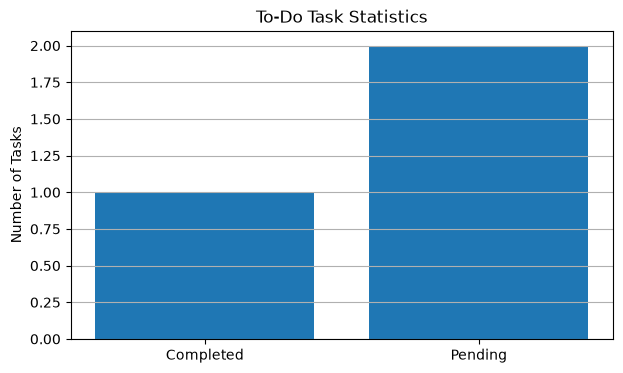

In [8]:

completed = sum(item["completed"] for item in tasks)
pending = len(tasks) - completed

plt.figure(figsize=(7, 4))
plt.bar(["Completed", "Pending"], [completed, pending])
plt.ylabel("Number of Tasks")
plt.title("To-Do Task Statistics")
plt.grid(axis="y")
plt.show()



### Step 9 — Test Removing a Task

The `remove` command deletes a task using its task number.


In [9]:

result = todo_agent.invoke({
    "command": "remove 2",
    "tasks": tasks
})

tasks = result["tasks"]

print(result["response"])
print()
print(result["tasks"])


Removed task: Study for exam

[{'task': 'Complete Python assignment', 'completed': True}, {'task': 'Submit project', 'completed': False}]



### Step 10 — Test Clearing Tasks

The `clear` command removes all tasks from the current state.


In [10]:

result = todo_agent.invoke({
    "command": "clear",
    "tasks": tasks
})

tasks = result["tasks"]

print(result["response"])
print("Number of remaining tasks:", len(tasks))


All tasks cleared.
Number of remaining tasks: 0



### Step 11 — Simulate State Changes

This example shows how the task state changes after different commands.


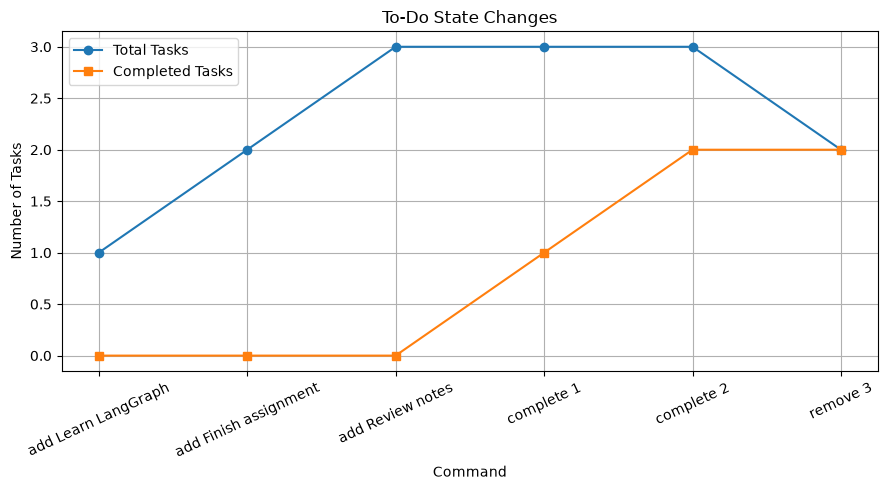

In [11]:

tasks = []
task_counts = []
completed_counts = []

commands = [
    "add Learn LangGraph",
    "add Finish assignment",
    "add Review notes",
    "complete 1",
    "complete 2",
    "remove 3"
]

for command in commands:
    result = todo_agent.invoke({
        "command": command,
        "tasks": tasks
    })

    tasks = result["tasks"]

    task_counts.append(len(tasks))
    completed_counts.append(
        sum(item["completed"] for item in tasks)
    )

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(commands) + 1), task_counts, marker="o", label="Total Tasks")
plt.plot(range(1, len(commands) + 1), completed_counts, marker="s", label="Completed Tasks")

plt.xticks(range(1, len(commands) + 1), commands, rotation=25)
plt.xlabel("Command")
plt.ylabel("Number of Tasks")
plt.title("To-Do State Changes")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



### Step 12 — Interactive Command-Line To-Do Agent

Use the following commands:

- `add <task>` — add a new task
- `view` — view all tasks
- `complete <number>` — mark a task as completed
- `remove <number>` — remove a task
- `clear` — remove all tasks
- `stats` — show task statistics
- `exit` — stop the agent


In [ ]:

# tasks = []

# print("To-Do Agent Started")
# print("Type 'exit' to stop.\n")

# while True:
#     command = input("You: ").strip()

#     if command.lower() == "exit":
#         print("Agent: Goodbye!")
#         break

#     result = todo_agent.invoke({
#         "command": command,
#         "tasks": tasks
#     })

#     tasks = result["tasks"]
#     print("Agent:", result["response"])
#     print()


To-Do Agent Started
Type 'exit' to stop.

Agent: Goodbye!



### Result

The LangGraph to-do agent successfully maintains task state across multiple commands. It can add, display, complete, remove, and clear tasks while generating a response for each operation.

### Conclusion

This assignment demonstrates a simple **command-line stateful agent using LangGraph**. LangGraph provides the workflow for processing commands, while the shared state maintains the current task list.

The project shows how an agent can maintain state and use that state to perform actions across multiple interactions.
